In [19]:
import sqlite3
import pandas as pd

# Connect and extract
conn = sqlite3.connect('../data/energy_data.db')
df = pd.read_sql_query("SELECT * FROM energy_master", conn)
conn.close()

# Normalize temporal index
df['timestamp'] = pd.to_datetime(df['timestamp'], utc=True)
df = df.set_index('timestamp')

In [20]:
# Total generation sum
df['total_gen'] = df[['wind', 'solar', 'nuclear', 'hydro', 'combined_cycle']].sum(axis=1)

# Cheap renewable share (Wind + Solar)
df['renewable_share'] = (df['wind'] + df['solar']) / df['total_gen']

In [21]:
import statsmodels.api as sm
from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error  # <-- Nueva importación

# Drop nulls for the model
df_clean = df.dropna(subset=['renewable_share', 'price_eur_mwh'])

# 1. Pearson Correlation
corr, p_value = pearsonr(df_clean['renewable_share'], df_clean['price_eur_mwh'])
print(f"Correlation: {corr:.2f} (p-value: {p_value})")
# A p-value < 0.05 shows the relationship is statistically significant.

# 2. Ordinary Least Squares (OLS) Regression
X = sm.add_constant(df_clean['renewable_share'])
y = df_clean['price_eur_mwh']
model = sm.OLS(y, X).fit()
print(model.summary())

# 3. Root Mean Squared Error (RMSE)  <-- Nuevo bloque
y_pred = model.predict(X)
rmse = mean_squared_error(y, y_pred) ** 0.5
print(f"\nRoot Mean Squared Error (RMSE): {rmse:.2f} €/MWh")

Correlation: -0.78 (p-value: 0.0)
                            OLS Regression Results                            
Dep. Variable:          price_eur_mwh   R-squared:                       0.603
Model:                            OLS   Adj. R-squared:                  0.603
Method:                 Least Squares   F-statistic:                 7.124e+04
Date:                Tue, 10 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:14:51   Log-Likelihood:            -2.5158e+05
No. Observations:               47000   AIC:                         5.032e+05
Df Residuals:                   46998   BIC:                         5.032e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const   

### Statistical Insights (Merit Order Effect)
- **Strong Inverse Correlation (-0.78):** As renewable energy penetration increases, market prices decrease.
- **High Explanatory Power (R-squared: 0.603):** The renewable share alone explains 60.3% of the price variance.
- **Economic Impact (Coef: -247.55):** Every 10% increase in renewable generation share reduces the market price by roughly 24.76 €/MWh.
- **Statistical Significance (p-value: 0.000):** The relationship is mathematically proven and not due to chance.
- **Baseline Deviation (RMSE: 51.10 €/MWh):** Actual prices deviate from the trend line by an average of 51.10 €/MWh, indicating that while renewables set the trend, other factors (like gas costs or demand spikes) still drive significant volatility.

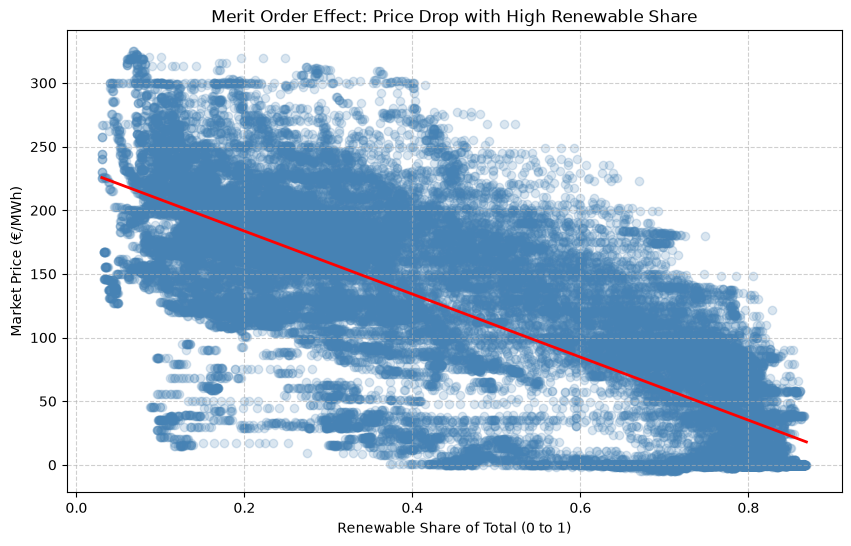

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.regplot(
    x='renewable_share', 
    y='price_eur_mwh', 
    data=df_clean, 
    scatter_kws={'alpha':0.2, 'color': 'steelblue'}, 
    line_kws={'color':'red', 'linewidth': 2}
)

plt.title('Merit Order Effect: Price Drop with High Renewable Share')
plt.xlabel('Renewable Share of Total (0 to 1)')
plt.ylabel('Market Price (€/MWh)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Visual Analysis:
* **Clear Negative Trend:** The red regression line visually validates the OLS model; market prices drop predictably as renewable generation increases.
* **Zero-Price Cannibalization:** As renewables surpass 60% (0.6), price variance shrinks drastically and clusters heavily at exactly 0 €/MWh. This highlights the "cannibalization effect," where abundant zero-marginal-cost energy clears the market at zero.

In [23]:
# Group renewable share into 20% bins and measure price volatility (standard deviation)
df_clean['share_bin'] = pd.cut(df_clean['renewable_share'], bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0])
volatility = df_clean.groupby('share_bin')['price_eur_mwh'].std()
print(volatility)

share_bin
(0.0, 0.2]    52.213142
(0.2, 0.4]    54.131491
(0.4, 0.6]    64.819644
(0.6, 0.8]    50.325807
(0.8, 1.0]    23.383546
Name: price_eur_mwh, dtype: float64


### Volatility Analysis by Renewable Share
* **High Volatility in Transition Zones (40% - 60%):** Price variance peaks (Std Dev: ~64.8 €/MWh) because the marginal price frequently toggles between expensive fossil fuels and cheap renewables.
* **Variance Collapse at High Penetration (>80%):** Volatility drops drastically (Std Dev: ~23.3 €/MWh). At this stage, renewables fully cover demand, pinning prices consistently near 0 €/MWh and significantly reducing market variance.

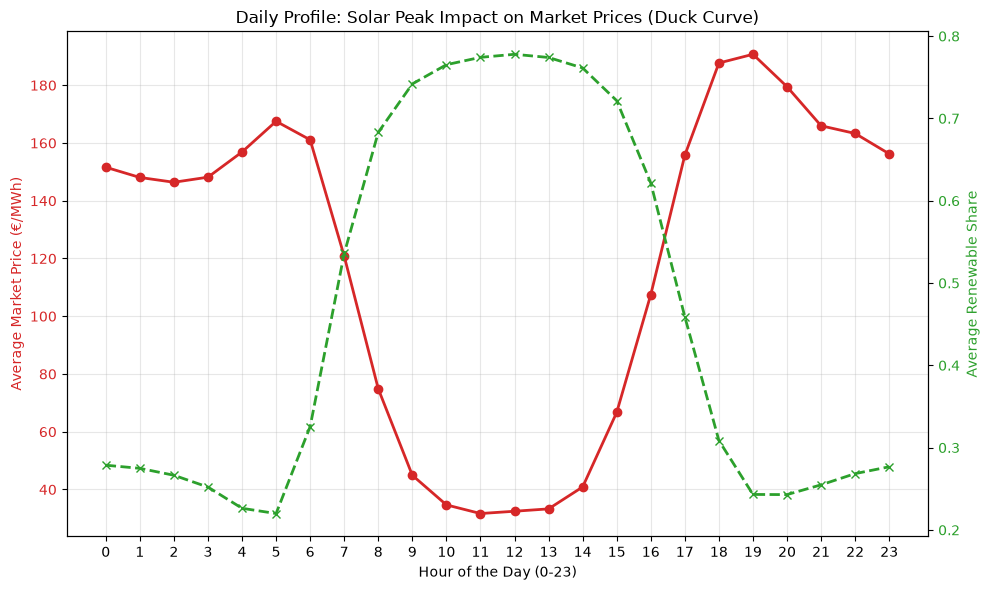

In [24]:
# Extract the hour from the datetime index
df_clean['hour'] = df_clean.index.hour

# Calculate average price and renewable share by hour
hourly_stats = df_clean.groupby('hour')[['price_eur_mwh', 'renewable_share']].mean()

# Dual-axis plot
fig, ax1 = plt.subplots(figsize=(10, 6))

# Left Y-axis: Price
color = 'tab:red'
ax1.set_xlabel('Hour of the Day (0-23)')
ax1.set_ylabel('Average Market Price (€/MWh)', color=color)
ax1.plot(hourly_stats.index, hourly_stats['price_eur_mwh'], color=color, linewidth=2, marker='o')
ax1.tick_params(axis='y', labelcolor=color)

# Right Y-axis: Renewable Share
ax2 = ax1.twinx()
color = 'tab:green'
ax2.set_ylabel('Average Renewable Share', color=color)
ax2.plot(hourly_stats.index, hourly_stats['renewable_share'], color=color, linewidth=2, linestyle='--', marker='x')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Daily Profile: Solar Peak Impact on Market Prices (Duck Curve)')
plt.xticks(range(0, 24))
fig.tight_layout()
ax1.grid(alpha=0.3)
plt.show()

### Daily "Duck Curve" Analysis
* **Midday Price Collapse (The Belly):** Between 10:00 and 14:00, renewable generation (driven by solar) peaks at nearly 80% of the energy mix. This massive influx of zero-marginal-cost energy drives the average market price down to its daily minimum of around 30 €/MWh.
* **Steep Evening Ramp-Up (The Neck):** As the sun sets and solar generation sharply declines after 16:00, the renewable share plummets. To cover the evening demand peak, expensive fossil fuels plants are fired up, sending prices soaring to their daily maximum of nearly 190 €/MWh around 19:00 - 20:00.
* **Inverse Relationship:** The intersection of the two lines at 07:00 and 16:00 visually confirms the Merit Order Effect on a daily scale. The hourly market price is almost entirely dictated by the availability of renewable energy.